# PJM DART Spread — Modeling & Baselines

## Open

In [37]:
from scripts.data.data_collection import TEST_DATA_PATH, TRAIN_DATA_PATH

train = pd.read_csv(INPUT_DATA_DIR / "train_features.csv", index_col="interval_start_utc", parse_dates=True)
test = pd.read_csv(INPUT_DATA_DIR / "test_features.csv", index_col="interval_start_utc", parse_dates=True)
feature = pd.concat([train, test]).sort_index()
feature.head()

,dart,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,month_1,month_2,month_3,month_4,...,rt_lmp_lag_24,dart_lag_48,rt_lmp_lag_48,dart_lag_168,rt_lmp_lag_168,dart_mean_24,dart_std_24,dart_mean_168,rt_lmp,da_lmp
interval_start_utc,,,,,,,,,,,,,,,,,,,,,
2019-01-08 00:00:00+00:00,9.763805,-0.965926,0.258819,0.0,1.0,0,True,False,False,False,...,21.826374,3.655929,20.873202,4.686802,19.863592,1.08701,1.77798,1.666105,23.929555,33.693360
2019-01-08 01:00:00+00:00,6.528033,-0.866025,0.500000,0.0,1.0,0,True,False,False,False,...,21.826374,3.421138,20.366383,4.157593,19.357343,1.08701,1.77798,1.666105,24.152211,30.680244
2019-01-08 02:00:00+00:00,3.975175,-0.707107,0.707107,0.0,1.0,0,True,False,False,False,...,21.826374,2.523884,20.696746,3.783138,18.809284,1.08701,1.77798,1.666105,23.346055,27.321230
2019-01-08 03:00:00+00:00,0.397876,-0.500000,0.866025,0.0,1.0,0,True,False,False,False,...,21.826374,-0.308093,22.333786,2.332116,18.482355,1.08701,1.77798,1.666105,22.323626,22.721502
2019-01-08 04:00:00+00:00,-0.105460,-0.258819,0.965926,0.0,1.0,0,True,False,False,False,...,21.826374,0.823267,18.934069,1.748180,18.052672,1.08701,1.77798,1.666105,20.584193,20.478733


## Dataset info

In [38]:
print(f"rows: {len(feature):,}   cols: {feature.shape[1]}")
print(f"date range: {feature.index.min()}  ->  {feature.index.max()}")
print()
feature.info()
print()
print("missing values per column:")
print(feature.isna().sum())

rows: 66,120   cols: 33
date range: 2019-01-08 00:00:00+00:00  ->  2026-07-31 23:00:00+00:00

<class 'pandas.DataFrame'>
DatetimeIndex: 66120 entries, 2019-01-08 00:00:00+00:00 to 2026-07-31 23:00:00+00:00
Data columns (total 33 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dart            66120 non-null  float64
 1   hour_sin        66120 non-null  float64
 2   hour_cos        66120 non-null  float64
 3   dow_sin         66120 non-null  float64
 4   dow_cos         66120 non-null  float64
 5   is_weekend      66120 non-null  int64  
 6   month_1         66120 non-null  bool   
 7   month_2         66120 non-null  bool   
 8   month_3         66120 non-null  bool   
 9   month_4         66120 non-null  bool   
 10  month_5         66120 non-null  bool   
 11  month_6         66120 non-null  bool   
 12  month_7         66120 non-null  bool   
 13  month_8         66120 non-null  bool   
 14  month_9         66120 non-null  bool

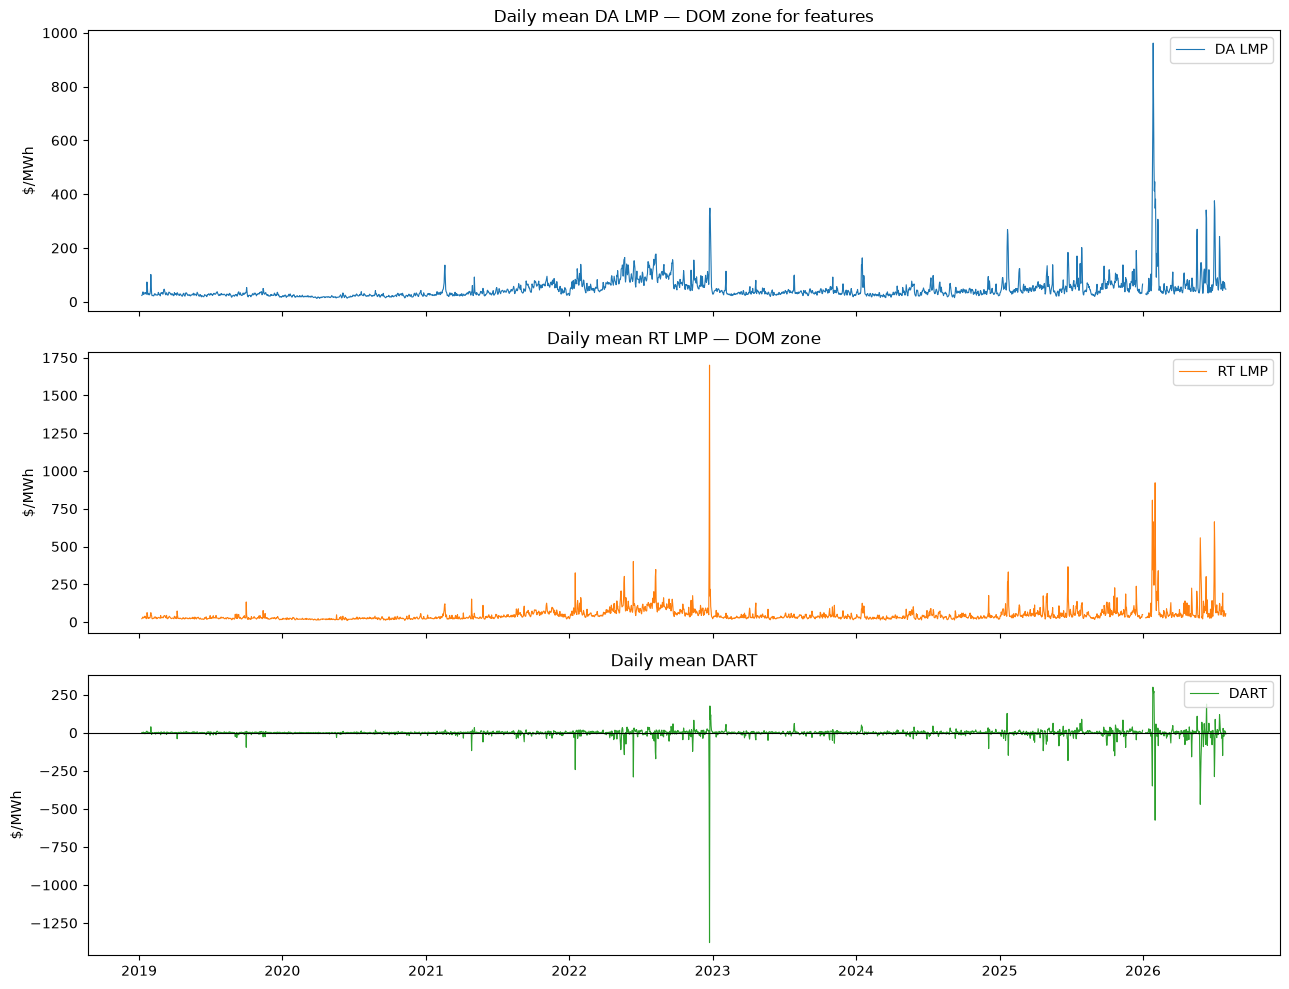

In [39]:
daily = feature.resample("D").mean()

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

axes[0].plot(daily.index, daily["da_lmp"], label="DA LMP", linewidth=0.8)
axes[0].set_ylabel("$/MWh")
axes[0].set_title("Daily mean DA LMP — DOM zone for features")
axes[0].legend()

axes[1].plot(daily.index, daily["rt_lmp"], label="RT LMP", linewidth=0.8, color="tab:orange")
axes[1].set_ylabel("$/MWh")
axes[1].set_title("Daily mean RT LMP — DOM zone")
axes[1].legend()

axes[2].plot(daily.index, daily["dart"],  label="DART", color="tab:green", linewidth=0.8)
axes[2].axhline(0, color="black", linewidth=0.8)
axes[2].set_ylabel("$/MWh")
axes[2].set_title("Daily mean DART")
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

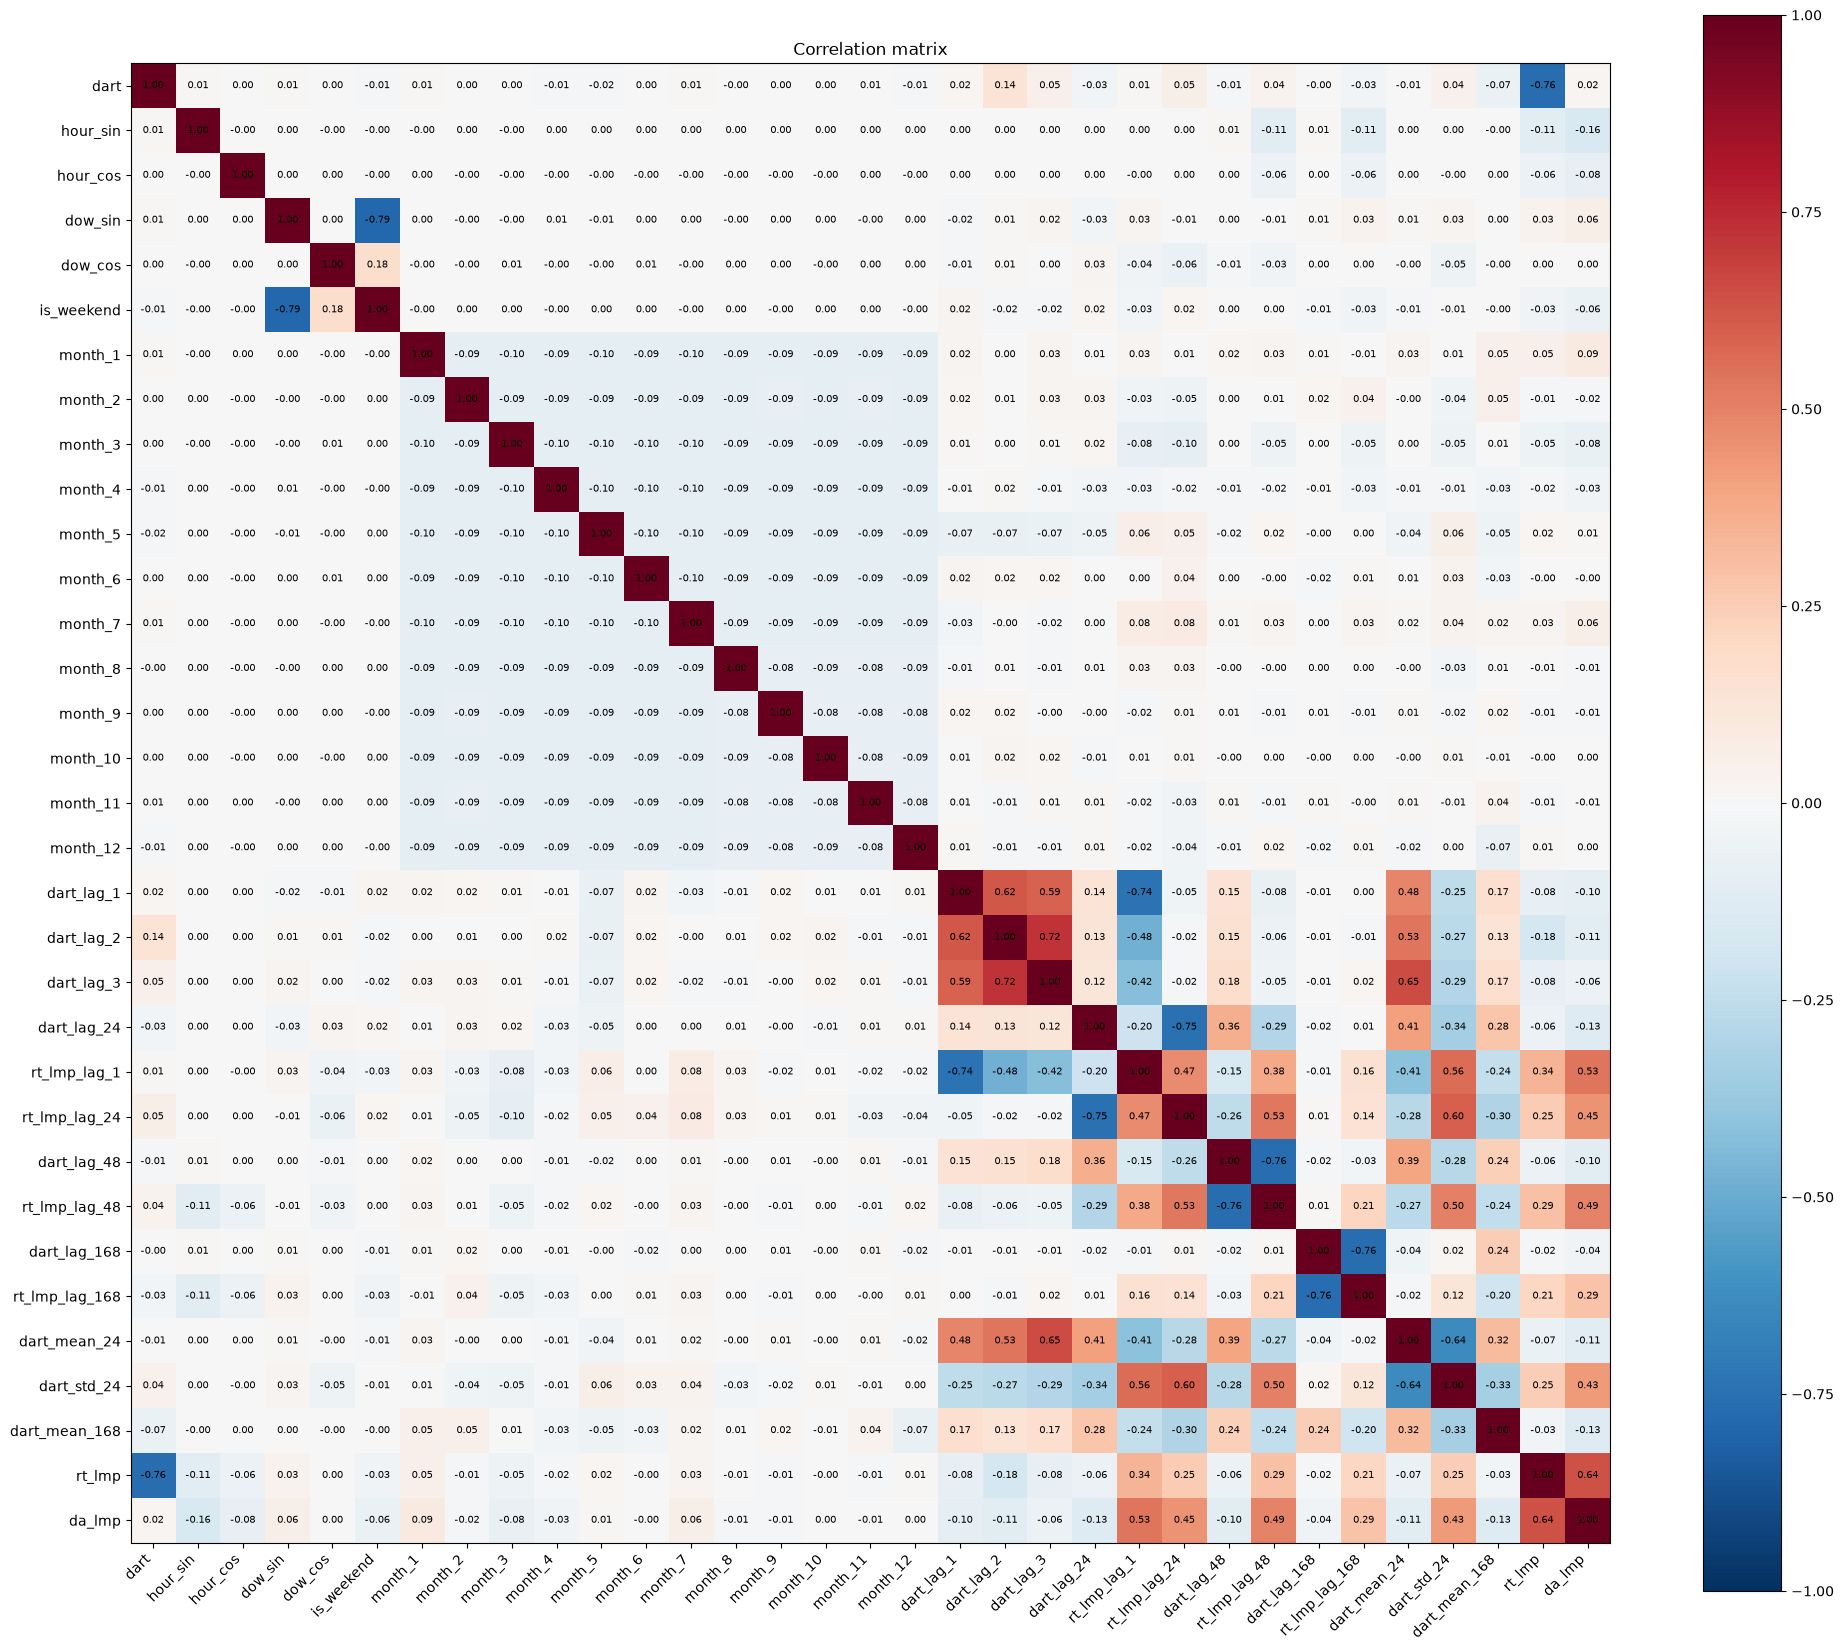

In [40]:
corr_matrix = feature.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(20, 20))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

## Cleaning

Removed in Phase 1 (`MIGRATION_PLAN.md`): this used to drop rows where `rt_lmp`/`da_lmp`
were IQR outliers before saving `features.csv`, which clipped `dart`'s tails from
±530 down to ±77 — exactly the failure `docs/audit.md` traces the old regression
setup back to. Outlier handling now lives in `build_features` (`scripts/data/features.py`)
as `dart_feat`, a causally winsorized copy used only to build lag/rolling features.
`dart` itself is never touched.

Phase 3 went further: `build_features` no longer emits `rt_lmp`/`da_lmp` (or any of
the old autocorrelation-heavy lag/rolling set) at all, so there's nothing left to
drop here — the feature matrix is README §4's ~13 columns from the start.

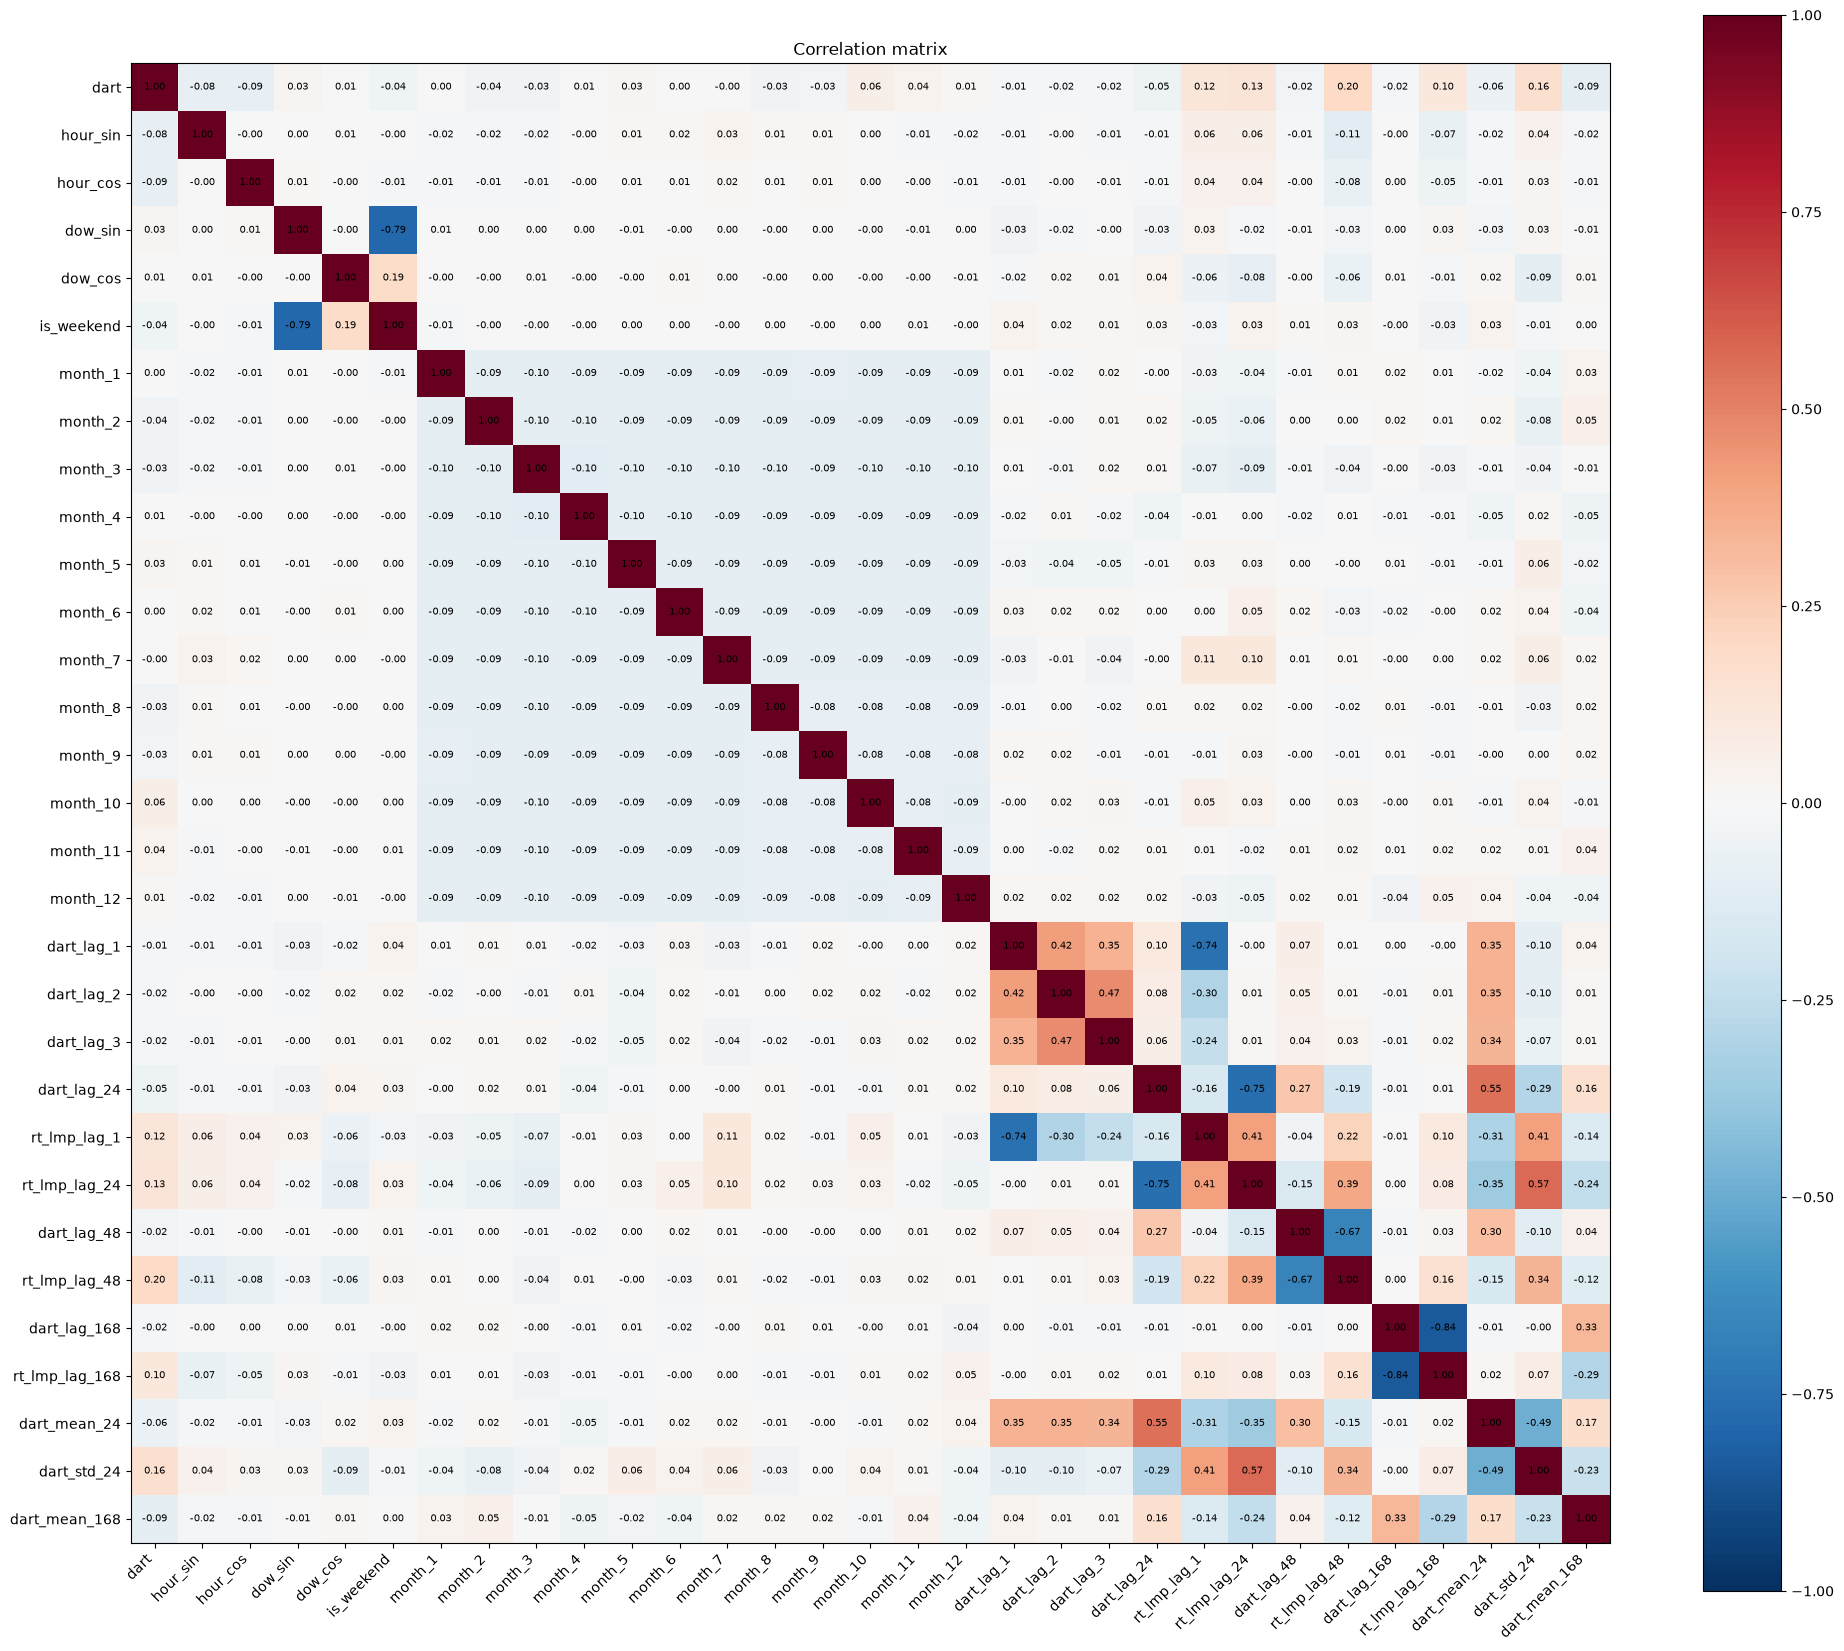

In [47]:
corr_matrix = feature.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(20, 20))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_yticklabels(corr_matrix.columns)
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

mean:     3.056
median:   2.370
std:      11.024
skew:     -0.126
kurtosis: 5.850
share > 0 (INC favorable): 71.0%
share < 0 (DEC favorable): 29.0%


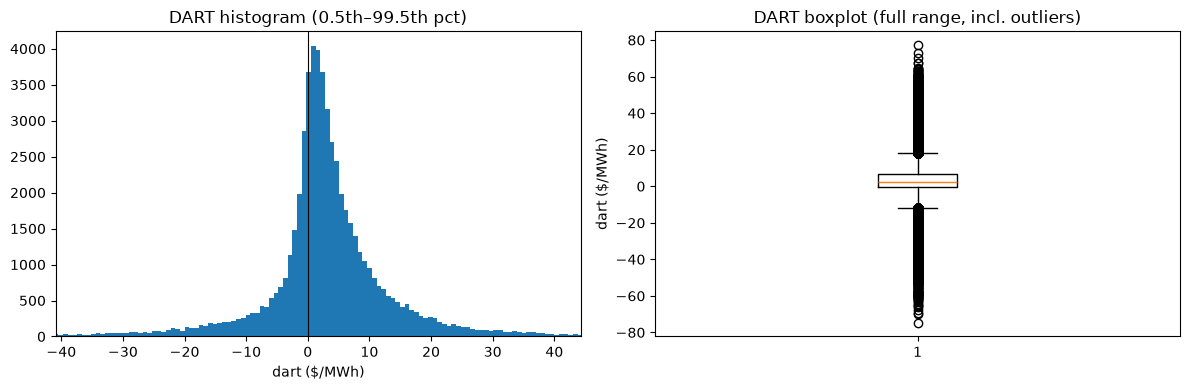

In [58]:
import matplotlib.pyplot as plt

print(f"mean:     {feature['dart'].mean():.3f}")
print(f"median:   {feature['dart'].median():.3f}")
print(f"std:      {feature['dart'].std():.3f}")
print(f"skew:     {feature['dart'].skew():.3f}")
print(f"kurtosis: {feature['dart'].kurtosis():.3f}")
print(f"share > 0 (INC favorable): {(feature['dart'] > 0).mean():.1%}")
print(f"share < 0 (DEC favorable): {(feature['dart'] < 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(feature["dart"], bins=200)
axes[0].set_xlim(feature["dart"].quantile(0.005), feature["dart"].quantile(0.995))
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("DART histogram (0.5th–99.5th pct)")
axes[0].set_xlabel("dart ($/MWh)")

axes[1].boxplot(feature["dart"], showfliers=True)
axes[1].set_title("DART boxplot (full range, incl. outliers)")
axes[1].set_ylabel("dart ($/MWh)")

plt.tight_layout()
plt.show()

In [46]:
corr_matrix['dart']

dart              1.000000
hour_sin         -0.080457
hour_cos         -0.085301
dow_sin           0.027487
dow_cos           0.007484
is_weekend       -0.042881
month_1           0.000177
month_2          -0.035246
month_3          -0.034309
month_4           0.005136
month_5           0.025112
month_6           0.004325
month_7          -0.002916
month_8          -0.034737
month_9          -0.025474
month_10          0.056928
month_11          0.035172
month_12          0.008315
dart_lag_1       -0.009637
dart_lag_2       -0.019321
dart_lag_3       -0.021708
dart_lag_24      -0.048652
rt_lmp_lag_1      0.119377
rt_lmp_lag_24     0.128954
dart_lag_48      -0.023507
rt_lmp_lag_48     0.201470
dart_lag_168     -0.018860
rt_lmp_lag_168    0.102745
dart_mean_24     -0.060260
dart_std_24       0.158428
dart_mean_168    -0.094131
Name: dart, dtype: float64

In [56]:
feature.to_csv('features.csv')

## Split & labels

Phase 4: chronological three-way split (train 2019-2023 / validation 2024 / test
2025-2026-07), `y_pos`/`y_neg` from the starting `(γ_pos, γ_neg)` in `scripts/config.py`.
Test is not touched until Phase 7 — only `tr`/`va` are used below.

In [ ]:
from scripts.config import GAMMA_NEG_START, GAMMA_POS_START
from scripts.data.labels import build_labels
from scripts.data.split import chronological_split

FEATURE_COLS = [c for c in feature.columns if c not in ("dart", "dart_feat")]

tr, va, te = chronological_split(feature)
print(f"train {len(tr):>6}  {tr.index.min()} .. {tr.index.max()}")
print(f"val   {len(va):>6}  {va.index.min()} .. {va.index.max()}")
print(f"test  {len(te):>6}  {te.index.min()} .. {te.index.max()}  (untouched)")

X_train, X_val = tr[FEATURE_COLS], va[FEATURE_COLS]
y_train = build_labels(tr["dart"], GAMMA_POS_START, GAMMA_NEG_START)
y_val = build_labels(va["dart"], GAMMA_POS_START, GAMMA_NEG_START)

print(f"\ntrain base rates: y_pos={y_train['y_pos'].mean():.3%}  y_neg={y_train['y_neg'].mean():.3%}")
print(f"val   base rates: y_pos={y_val['y_pos'].mean():.3%}  y_neg={y_val['y_neg'].mean():.3%}")

## Train

Phase 5: two independent logistic regressions (README §7) — standardized features,
`class_weight="balanced"`, L2. Trained on train only.

In [ ]:
from scripts.models.logistic import fit_spike_classifiers

models = fit_spike_classifiers(X_train, y_train["y_pos"], y_train["y_neg"])

p_pos_val = pd.Series(models["pos"].predict_proba(X_val)[:, 1], index=X_val.index)
p_neg_val = pd.Series(models["neg"].predict_proba(X_val)[:, 1], index=X_val.index)

## Validation check (Phase 5 acceptance)

At the default 0.5 threshold — not the tuned `τ_pos`/`τ_neg` from Phase 6, just a
sanity check that precision beats the base rate. High recall here is expected and
not a target: `class_weight="balanced"` pushes the boundary low, and Phase 6's
threshold grid (README §8: `τ` typically 0.70-0.90) is what makes the model trade
rarely and precisely. Test is not evaluated here or anywhere before Phase 7.

In [ ]:
from scripts.evaluation import score_spikes

pred_pos = (p_pos_val >= 0.5).astype(int)
pred_neg = (p_neg_val >= 0.5).astype(int)

pos_scores = score_spikes(y_val["y_pos"], pred_pos)
neg_scores = score_spikes(y_val["y_neg"], pred_neg)

print("INC (y_pos) validation @ 0.5:", pos_scores)
print("DEC (y_neg) validation @ 0.5:", neg_scores)

assert pos_scores["precision"] > pos_scores["base_rate"], "INC precision should beat the base rate"
assert neg_scores["precision"] > neg_scores["base_rate"], "DEC precision should beat the base rate"